# Memory Maze Data Exploration

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import random


# List all trajectories
trajectories = glob.glob('data/*/*.npz')
print(f"Found {len(trajectories)} trajectories")
print(f"First few: {trajectories[:3]}")

Found 3900 trajectories
First few: ['data\\eval\\20220920T134216-1000.npz', 'data\\eval\\20220920T134217-1000.npz', 'data\\eval\\20220920T134218-1000.npz']


In [2]:
# Load a random trajectory
traj_path = random.choice(trajectories)
episode = np.load(traj_path)
episode = {key: episode[key] for key in episode.files}

print(f"Loaded: {traj_path}")
print(f"Keys: {episode.keys()}")
print(f"Image shape: {episode['image'].shape}")
print(f"Agent pos shape: {episode['agent_pos'].shape}")
print(f"Maze layout shape: {episode['maze_layout'].shape}")

Loaded: data\train0\20220923T105743-1000.npz
Keys: dict_keys(['image', 'target_color', 'agent_pos', 'agent_dir', 'targets_vec', 'targets_pos', 'target_vec', 'target_pos', 'maze_layout', 'action', 'reward', 'terminal', 'reset'])
Image shape: (1001, 64, 64, 3)
Agent pos shape: (1001, 2)
Maze layout shape: (1001, 9, 9)


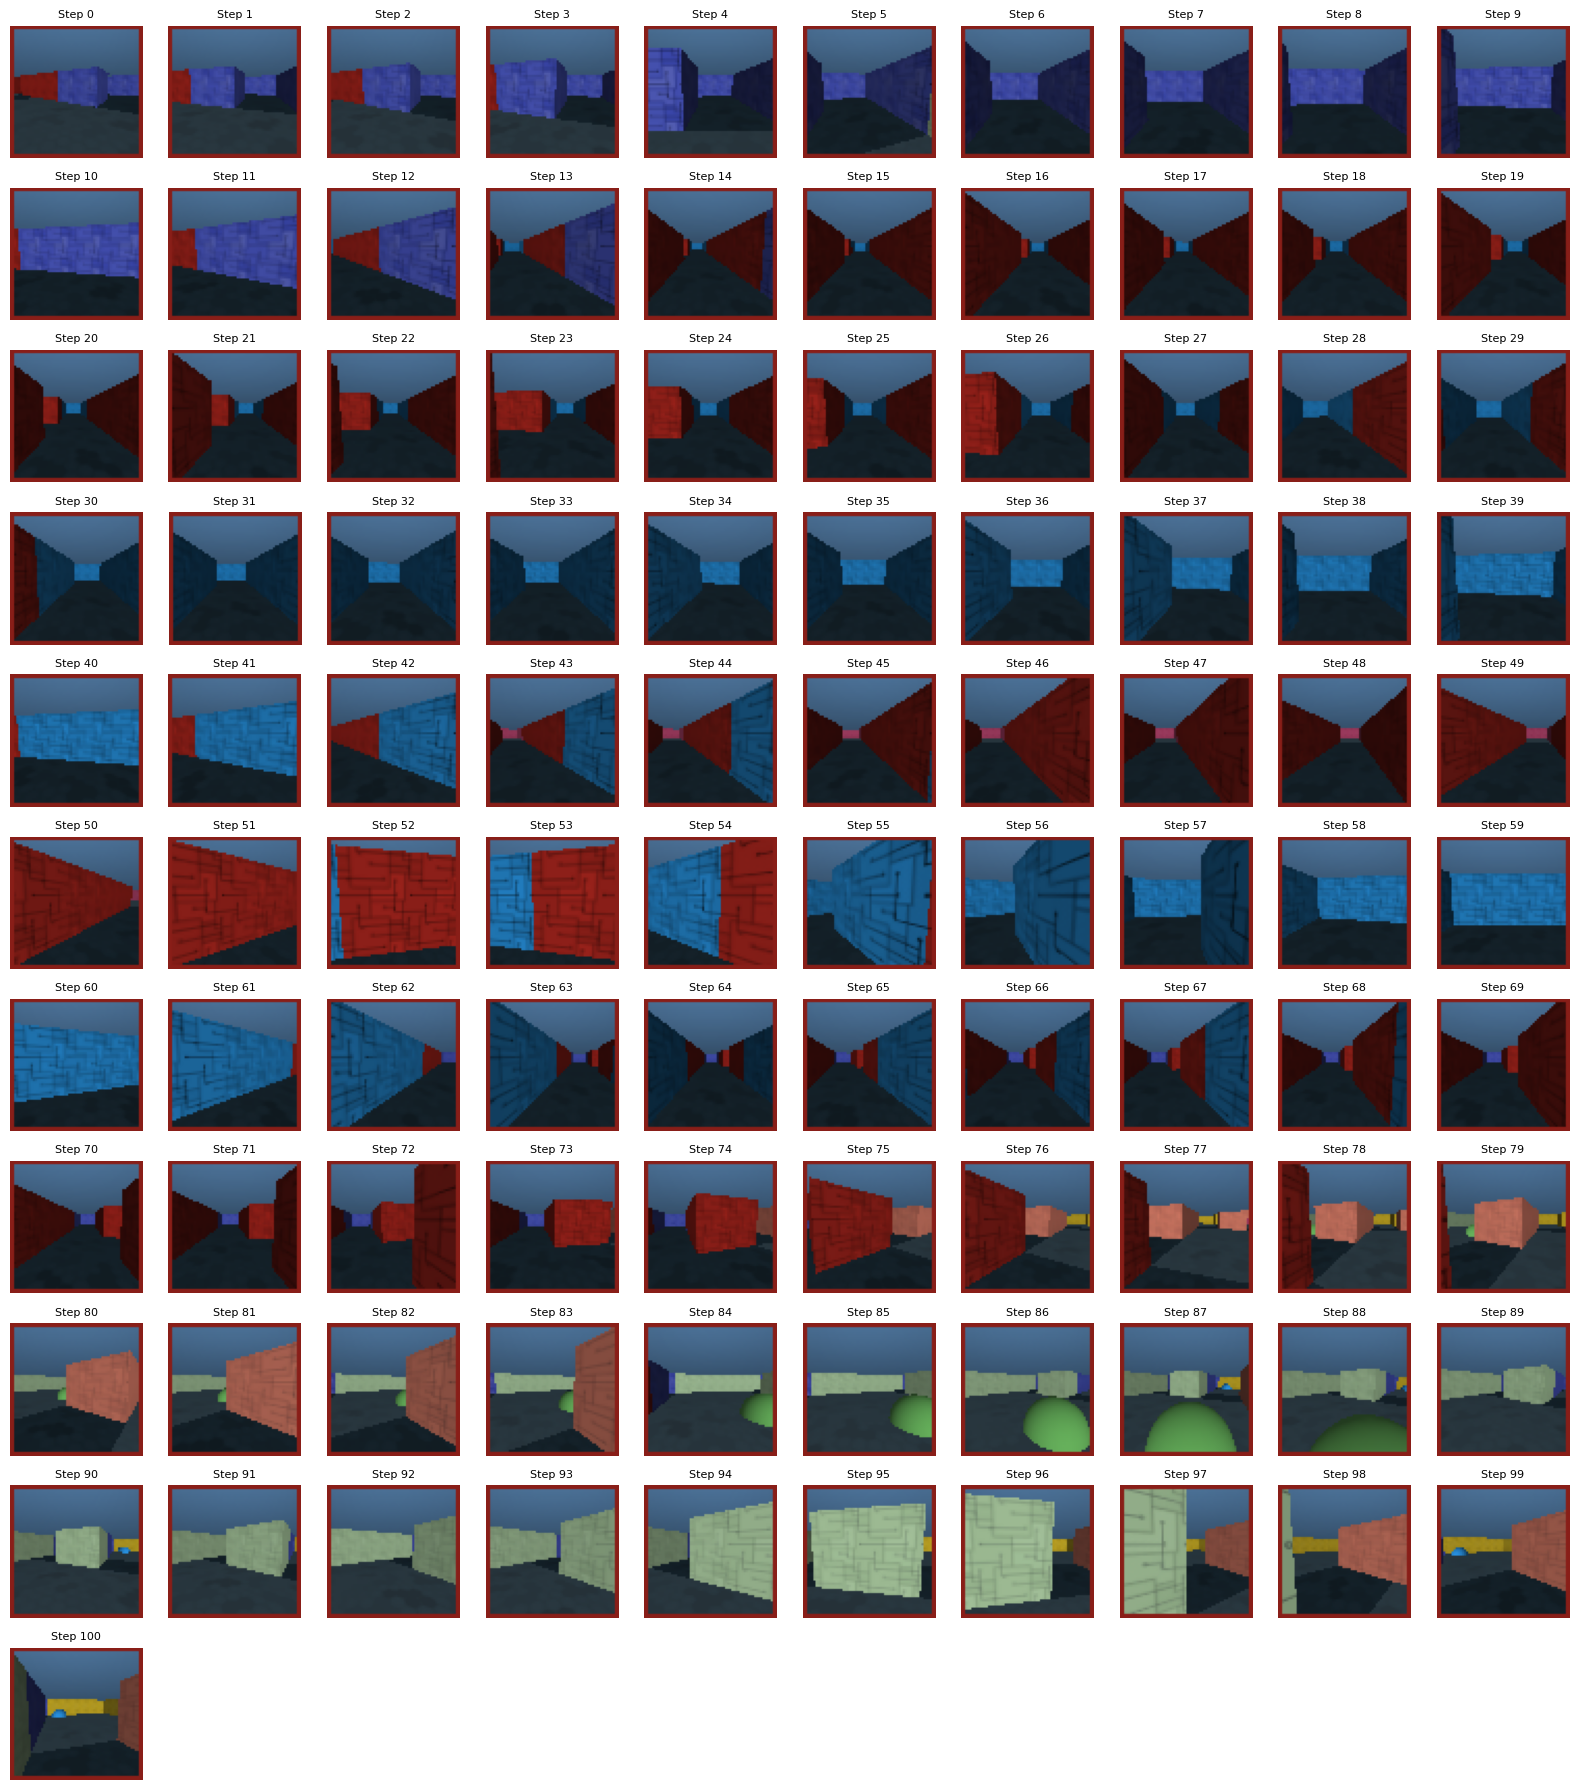

In [3]:
# Display a few frames (step size 1, steps 0-100)
fig, axes = plt.subplots(11, 10, figsize=(16, 18))
axes = axes.flatten()

for i in range(101):
    axes[i].imshow(episode['image'][i])
    axes[i].set_title(f"Step {i}", fontsize=8)
    axes[i].axis('off')

# Hide unused axes
for i in range(101, 110):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

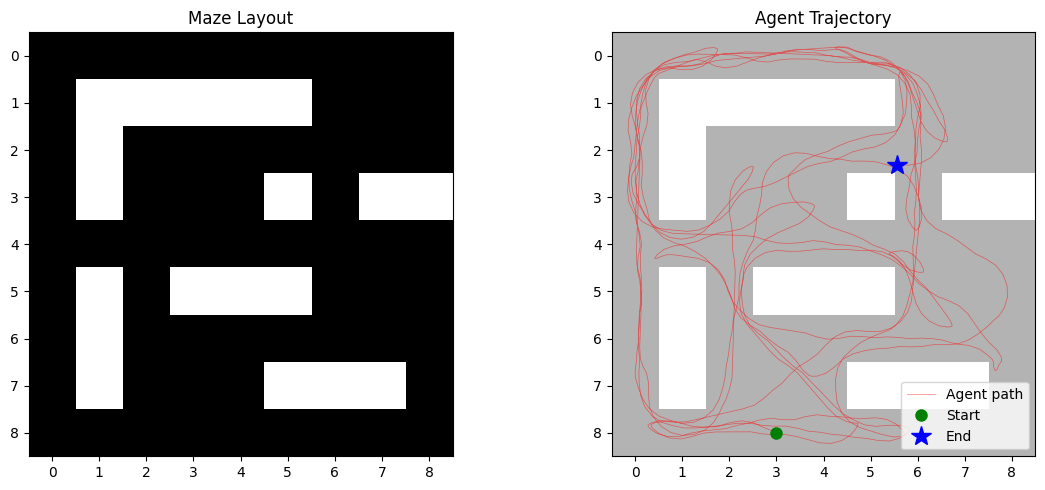

In [4]:
# Display maze layout with agent trajectory
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Maze layout - take first frame since it's time-varying
maze = episode['maze_layout'][0]
ax1.imshow(maze, cmap='gray_r')
ax1.set_title('Maze Layout')

# Agent trajectory
positions = episode['agent_pos']
# Shift by 0.5 to align with cell centers in imshow
x_pos = positions[:, 0] - 0.5
y_pos = positions[:, 1] - 0.5

ax2.imshow(maze, cmap='gray_r', alpha=0.3)
ax2.plot(x_pos, y_pos, 'r-', alpha=0.5, linewidth=0.5, label='Agent path')
ax2.plot(x_pos[0], y_pos[0], 'go', markersize=8, label='Start')
ax2.plot(x_pos[-1], y_pos[-1], 'b*', markersize=15, label='End')
ax2.set_title('Agent Trajectory')
ax2.legend()
ax2.set_xlim(-0.5, 8.5)
ax2.set_ylim(-0.5, 8.5)
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

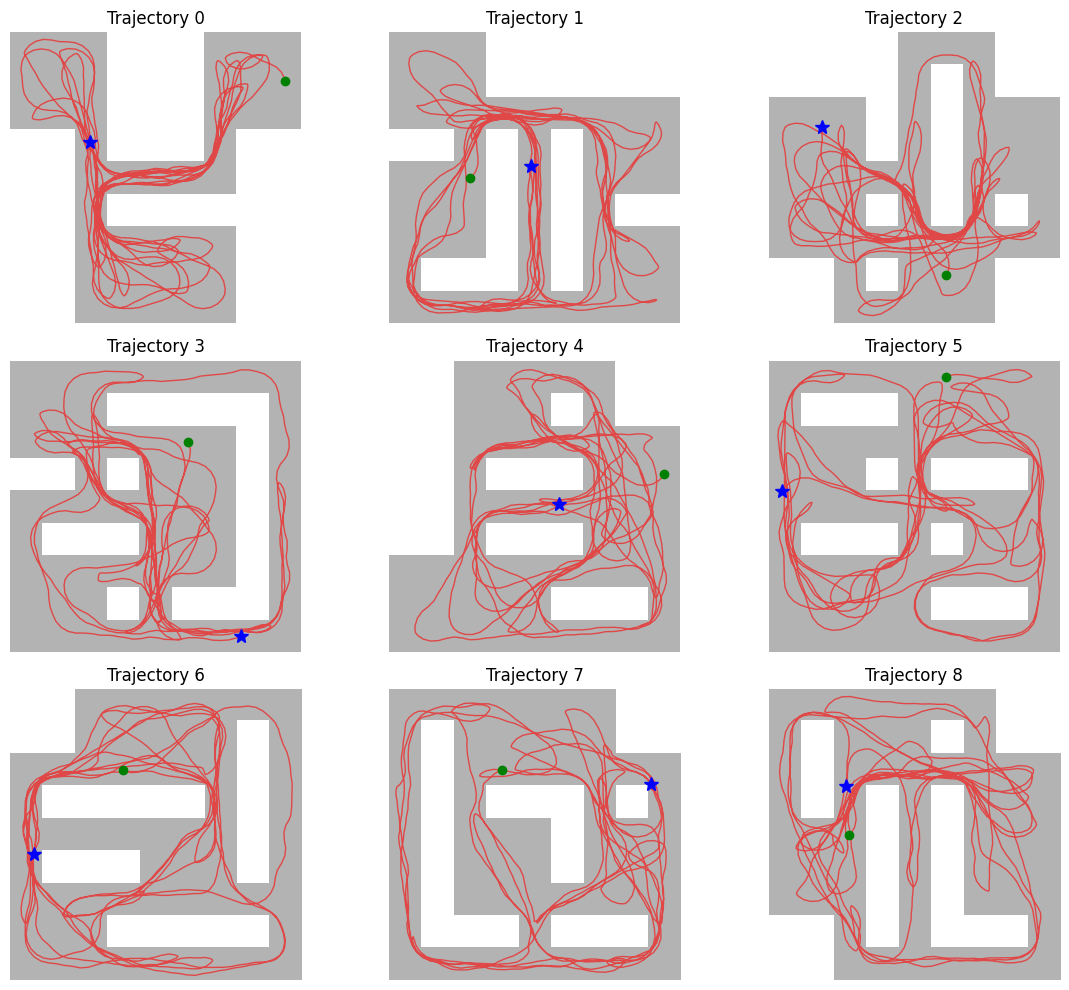

In [5]:
# Show a few more random trajectories
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.flatten()

for idx in range(9):
    traj = np.load(random.choice(trajectories))
    traj = {key: traj[key] for key in traj.files}
    
    maze = traj['maze_layout'][0]
    pos = traj['agent_pos']
    
    axes[idx].imshow(maze, cmap='gray_r', alpha=0.3)
    axes[idx].plot(pos[:, 0] - 0.5, pos[:, 1] - 0.5, 'r-', alpha=0.6, linewidth=1)
    axes[idx].plot(pos[0, 0] - 0.5, pos[0, 1] - 0.5, 'go', markersize=6)
    axes[idx].plot(pos[-1, 0] - 0.5, pos[-1, 1] - 0.5, 'b*', markersize=10)
    axes[idx].set_xlim(-0.5, 8.5)
    axes[idx].set_ylim(-0.5, 8.5)
    axes[idx].invert_yaxis()
    axes[idx].set_title(f'Trajectory {idx}')
    axes[idx].axis('off')

plt.tight_layout()
plt.show()